# A network start for volume holograms: does a learned phase beat the GS loop on three planes

**Question:** Can a network that learned the physics give a better hologram for a three-plane target than the volumetric Gerchberg-Saxton loop at the same cost, and is it better by the volume's accuracy, by the traps' own numbers, or only by one of them?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 and 02 of topic 01-fourier-optics (the focal field and the trap metrics) and notebooks 01 and 02 of this topic (the network's input and its training)
- **Method run:** M17, the released multi-plane network `cgh-net` (a DeepCGH-style model), against the classical M19
- **Reading time:** about 50 minutes; the notebook runs in about 90 seconds

## Objectives

A hologram for traps at several depths is harder than one for a single plane, because the light has to be right in a volume and every plane sees the light meant for the others. You will build a three-plane target from the lattice of case C05, run the classical volumetric Gerchberg-Saxton loop (M19) on it and watch its accuracy move with the iteration count, run the released network of the product in one pass, read what each hologram does at the three planes, and then test the claim on eight more volumes. At the end you will know on which measure the network wins, by how much, on which measure it loses, and why the product's hybrid, which hands the network's phase to M19, never keeps the refinement.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.31.1
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The network is the product's released ONNX graph, the same file the browser runs, read through onnxruntime. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import json
import sys
import time
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics, modes
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.learned import convert, evaluation, generators
from pipeline.model.holo.methods.baseline import m19_multiplane
from pipeline.model.holo.methods.learned import m17_cgh_net

for name in ("numpy", "matplotlib", "onnxruntime"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.31.1


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic. The case is written by the product and the network was trained on targets drawn from a seeded generator, so no third-party dataset applies and the repository licence covers every file.
- Files read: `data/examples/cases.json` (case C05, 51 traps on three planes), the released graph `models/cgh-net.onnx` with its card `models/cgh-net.json`, and the product's own generator of test volumes, which the second half of the notebook calls.

Case C05 was written for a 256 by 256 pixel SLM, and the network was trained for 128 by 128 pixels with no padding. The next cell keeps the optics of the case (1064 nm, a 2.4 mm focal length, 10 um pixels) and sets the grid to the network's, which the cell then reports in focal bins and Rayleigh ranges.

In [2]:
# case C05, three planes of traps: its optics, taken to the 128 x 128 pixel grid the network was trained for
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C05_multiplane_vortices"]
setup = replace(setup_of(rec), n_pix=128, pad=1)
bin_m, zr = focal_bin_m(setup), convert.rayleigh_range_m(setup)
print(f"wavelength {setup.wavelength_m * 1e9:.0f} nm, focal length {setup.focal_m * 1e3:.1f} mm")
print(f"one focal bin = {bin_m * 1e6:.3f} um, one SLM-limited Rayleigh range = {zr * 1e6:.2f} um")
print(f"the case has {len(rec['target']['traps'])} traps on the planes z = -10, 0 and +10 um")

wavelength 1064 nm, focal length 2.4 mm
one focal bin = 1.995 um, one SLM-limited Rayleigh range = 4.76 um
the case has 51 traps on the planes z = -10, 0 and +10 um


## Method

**The target.** A volume target is a set of point voxels, each on one of three planes at $z = -8$, $0$ and $+8$ Rayleigh ranges of the SLM aperture, $z_R = \lambda f^2 / (\pi R^2)$ with $R = N p / 2$; with this unit a lens term of $Z$ rad at the edge of the aperture moves the focus by $Z$ ranges, which is why the network is independent of the wavelength and the focal length. The target's lateral positions are whole focal bins.

**The classical loop, M19.** Whyte and Courtial (2005, https://doi.org/10.1088/1367-2630/7/1/117) treat the hologram and the volume as a three-dimensional Fourier pair. With $K$ the field on the Ewald sphere in the $k$-space volume and $a_m$ the target amplitude at voxel $m$, one iteration is

$$U = \mathcal{F}_{3D} K, \qquad U' = a_m e^{i \arg U}\ \text{at the target voxels, } 0 \text{ elsewhere}, \qquad \phi = \arg\big(\mathcal{F}_{3D}^{-1} U'\big)\big|_{\text{sphere}},$$

and the new SLM amplitude is reset to the input beam. It optimises the voxels it is given and nothing else, a fact that matters at the end.

**The measure.** DeepCGH (Eybposh et al. 2020, https://doi.org/10.1364/OE.399624) scores a volume by the accuracy $AC = \frac{1}{P}\sum_p 2\sum T_p I_p / (\sum T_p^2 + \sum I_p^2)$ over $P$ planes, with $T_p$ the target and $I_p$ the hologram's intensity at plane $p$, both normalised to unit sum. The product uses this definition for the network's loss, for the baseline and for the evaluation (the paper's own formula was not read, so this is the product's reading of it). $AC$ is 1 for a perfect copy of the target images, including their blur.

**The fair comparison.** A network pass costs less than one iteration of M19, and the notebook checks it. So a hybrid that spends $k$ iterations after the network costs less than M19 at $k + 1$ iterations, and every comparison below gives M19 the extra iteration.

The first step builds the target. The case's 17-trap triangular lattice (8 um apart) is snapped to whole bins and repeated on the three planes, which gives 51 traps. The twelve vortex traps of the case are dropped, because the network does not take a charge.

In [3]:
# snap the case's lattice to whole bins and move its three planes to the network's -8, 0 and +8 Rayleigh ranges
dz = m17_cgh_net.plane_dz_m(setup)  # the axial voxel pitch M19 needs: the spacing of the planes
plane_of = {-10.0: -1, 0.0: 0, 10.0: 1}
traps = []
for t in rec["target"]["traps"]:
    x_bin, y_bin = round(t["x_um"] * 1e-6 / bin_m), round(t["y_um"] * 1e-6 / bin_m)
    traps.append(Trap(t["id"], x_bin * bin_m, y_bin * bin_m, plane_of[t["z_um"]] * 8 * zr))
target = Target.from_traps(TrapSet(traps))
plane_index = np.rint(target.traps.z_m / (8 * zr)).astype(int)
dropped = int(np.sum([t["charge"] != 0 for t in rec["target"]["traps"]]))
print("traps per plane (z = -8, 0, +8 zR):", np.bincount(plane_index + 1).tolist())
print("lattice pitch in bins:", round(8e-6 / bin_m, 2), "| vortex charges dropped:", dropped)

traps per plane (z = -8, 0, +8 zR): [17, 17, 17]
lattice pitch in bins: 4.01 | vortex charges dropped: 12


The lattice is 4.01 bins apart, so snapping it moves no trap by more than half a bin, 17 traps sit on each plane and every trap has its own voxel, which M19 requires. The next cell asks the product for the network's input: one image per plane holding the square root of a unit-energy intensity, each trap drawn as a Gaussian spot one bin wide. The figure shows what the network is asked to produce.

input (3, 128, 128) | energy per plane [1.0, 1.0, 1.0]


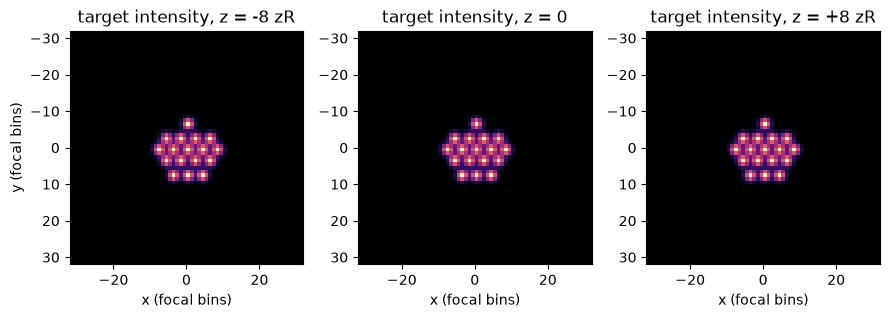

In [4]:
# the network's input: one unit-energy amplitude image per plane, drawn as the intensity the network is asked for
DEPTHS = ("-8 zR", "0", "+8 zR")
amps = m17_cgh_net.planes_from_traps(setup, target.traps)[0]
print("input", amps.shape, "| energy per plane", (amps.astype(float) ** 2).sum(axis=(1, 2)).round(3).tolist())
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, img, z in zip(axes, amps, DEPTHS):
    ax.imshow(img[32:96, 32:96] ** 2, cmap="magma", extent=(-32, 32, 32, -32))
    ax.set_title(f"target intensity, z = {z}")
    ax.set_xlabel("x (focal bins)")
axes[0].set_ylabel("y (focal bins)")
fig.tight_layout()
plt.show()

The three panels are the same lattice, because the case puts the same 17 positions on every plane; only the depth differs. Each spot is about two bins across, which is the resolution of the focal grid, so the spots of a 4-bin lattice nearly touch. The images say nothing yet about the light between the planes: a hologram that makes these three images exactly would still have to survive the defocus between them, and the next step measures how the classical loop copes. It runs M19 from the random start of the engine and keeps the phase at 1, 2, 4, 8, 16 and 30 iterations by continuing the same run, which gives the same result as separate runs because the loop's only state is the phase.

In [5]:
# volumetric GS (M19) continued from its own phase: the accuracy after 1, 2, 4, 8, 16 and 30 iterations
marks = (1, 2, 4, 8, 16, 30)
phis, phi_now, done = {}, None, 0
for k in marks:
    res = m19_multiplane.run(setup, target, budget=Budget(k - done), rng=Rng(1), init=phi_now, dz_m=dz)
    phi_now, done = res.phi, k
    phis[k] = phi_now
ac_m19 = {k: evaluation.plane_accuracy(amps, phis[k], setup) for k in marks}
for k in marks:
    print(f"M19 at {k:2d} iterations AC {ac_m19[k]:.4f}")

M19 at  1 iterations AC 0.7220
M19 at  2 iterations AC 0.7244
M19 at  4 iterations AC 0.7245
M19 at  8 iterations AC 0.7290
M19 at 16 iterations AC 0.7423
M19 at 30 iterations AC 0.7417


## State of the art

The state of the art for this problem is the learned hologram of DeepCGH (Eybposh et al. 2020): a U-Net takes the target images of all the planes and returns one SLM phase, and it is trained without labels, by making the accuracy $AC$ itself the loss through a differentiable propagation to every plane. The paper reports it at least 10 times faster than Gerchberg-Saxton and 9 to 43 percent more accurate on its own simulated volumes (the dossier of the product records these figures from the paper's text). DinHot's M17 is that setting at the size of a browser model: a U-Net of 0.99 million parameters in a 4.7 MB ONNX graph, three planes of 128 by 128 bins in, one 128 by 128 phase out, trained for 16000 steps on seeded random, lattice, ring and mixed volumes. Its card records the training, and a model that did not meet its criterion would not be released.

One pass of the network is one call of the method with the refinement switched off. The cell first warms the session, then times a network pass against one iteration of M19. The times themselves vary from machine to machine, so only the comparison is printed.

In [6]:
# one forward pass of the released network, timed against one iteration of the volumetric GS (best of three)
m17_cgh_net.run(setup, target, budget=Budget(1), rng=Rng(1), refine=False)  # warm-up: loads the ONNX session
net = m17_cgh_net.run(setup, target, budget=Budget(1), rng=Rng(1), refine=False)
times_net, times_iter = [], []
for _ in range(3):
    t0 = time.perf_counter()
    m17_cgh_net.run(setup, target, budget=Budget(1), rng=Rng(1), refine=False)
    times_net.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    m19_multiplane.run(setup, target, budget=Budget(1), rng=Rng(1), dz_m=dz)
    times_iter.append(time.perf_counter() - t0)
t_net, t_iter = min(times_net), min(times_iter)
print("provenance:", net.meta["provenance"], "| phase", net.phi.shape)
print(f"phase range {net.phi.min():.2f} to {net.phi.max():.2f} rad")
print("one network pass is cheaper than one M19 iteration:", t_net < t_iter)

provenance: real | phase (128, 128)
phase range -3.14 to 3.14 rad
one network pass is cheaper than one M19 iteration: True


The provenance reads `real`: the released graph answered, not the baseline that the catalog promises when the model is absent. The phase is a 128 by 128 array wrapped to the interval from minus pi to pi, and a pass is cheaper than one iteration of M19, so the comparison rule of the Method section holds. The next cell measures what that phase does. It refocuses the hologram to each plane by subtracting the plane's lens term, takes the engine's focal FFT and normalises, then scores each plane with the accuracy of the product's own evaluation module.

In [7]:
# what a phase does at the three planes: refocus by the plane's lens term, then the engine's focal FFT
def plane_images(phi):
    images = []
    for z in (-8, 0, 8):
        field = forward.fft_focal_field(phi - modes.lens_phase(setup, z * zr), setup)
        intensity = np.abs(field) ** 2
        images.append(intensity / intensity.sum())
    return np.array(images)


per_plane = [evaluation.plane_accuracy(amps[k:k + 1], net.phi, setup, (z,)) for k, z in enumerate((-8.0, 0.0, 8.0))]
print("accuracy AC per plane:", np.round(per_plane, 4).tolist(), "| mean", round(float(np.mean(per_plane)), 4))
ac_net = evaluation.plane_accuracy(amps, net.phi, setup)
print("volume accuracy from the product's own function:", round(ac_net, 4))

accuracy AC per plane: [0.7372, 0.7331, 0.7652] | mean 0.7452
volume accuracy from the product's own function: 0.7452


The accuracy is 0.7372, 0.7331 and 0.7652 on the three planes and 0.7452 on average, and the two lines at the end agree because the function that scores the volume is the one that scores each plane. A value of 0.75 does not mean three quarters of the traps are right: $AC$ compares whole images, so the blur of the spots and the light between them are part of the score. The outer planes are close to the middle one, which says the network handles the defocus rather than only the in-focus plane. The next figure puts the target above the network's intensity at the three planes.

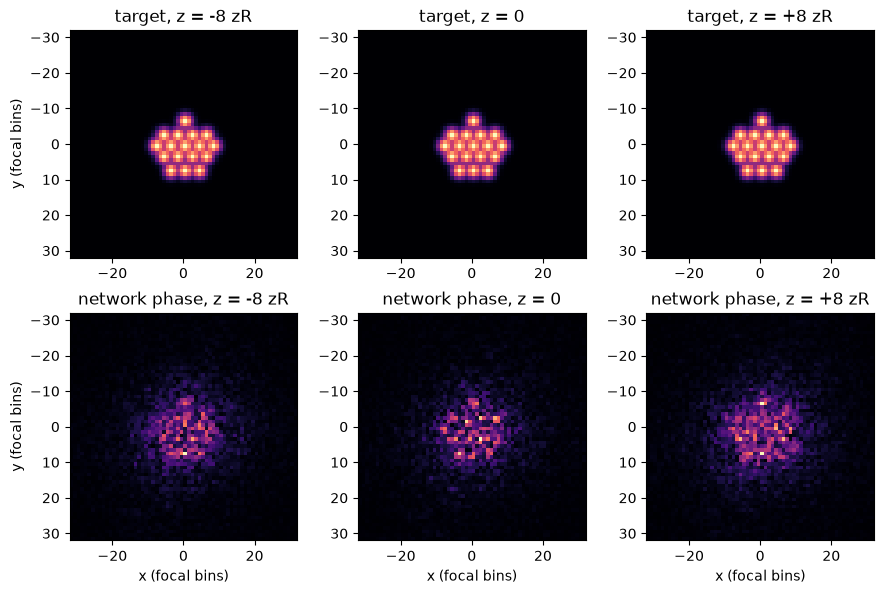

In [8]:
# the network's three planes under the target, on a square-root scale so the weak light around the spots shows
net_images = plane_images(net.phi)
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for k, z in enumerate(DEPTHS):
    axes[0, k].imshow(amps[k, 32:96, 32:96], cmap="magma", extent=(-32, 32, 32, -32))
    axes[1, k].imshow(np.sqrt(net_images[k, 32:96, 32:96]), cmap="magma", extent=(-32, 32, 32, -32))
    axes[0, k].set_title(f"target, z = {z}")
    axes[1, k].set_title(f"network phase, z = {z}")
    axes[1, k].set_xlabel("x (focal bins)")
axes[0, 0].set_ylabel("y (focal bins)")
axes[1, 0].set_ylabel("y (focal bins)")
fig.tight_layout()
plt.show()

The top row is the target; the bottom row is the light the network's phase makes at the same three depths, drawn as an amplitude so that the weak light shows. The lattice is recognisable in every panel, but the network's spots differ in brightness, and a halo of speckle around the lattice carries part of the power. The figure shows that the network does not make a clean copy; it does not show how much a different method would do better, and it does not show the traps' intensities, which are the point of a trap array. Both questions need the baseline, so the next figure sets the classical loop's accuracy, iteration by iteration, against the network's single value.

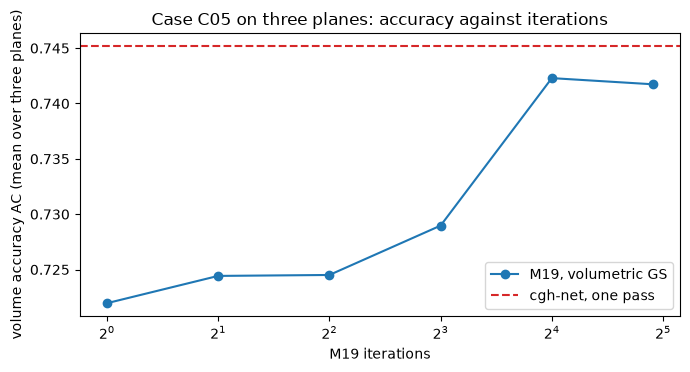

In [9]:
# the accuracy of M19 against its iteration count, with the network's single pass as a flat line
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(marks, [ac_m19[k] for k in marks], "o-", label="M19, volumetric GS")
ax.axhline(ac_net, color="C3", linestyle="--", label="cgh-net, one pass")
ax.set_xscale("log", base=2)
ax.set_xlabel("M19 iterations")
ax.set_ylabel("volume accuracy AC (mean over three planes)")
ax.set_title("Case C05 on three planes: accuracy against iterations")
ax.legend()
fig.tight_layout()
plt.show()

The dashed line is the network, 0.7452, and the points are M19 at 1, 2, 4, 8, 16 and 30 iterations: 0.7220, 0.7244, 0.7245, 0.7290, 0.7423 and 0.7417. The axis spans only 0.025, so the differences are small in absolute terms, and the loop does not pass the network within 30 iterations on this target. M19 gains most between 8 and 16 iterations and then stops, which is the plateau of an algorithm that is not optimising this measure. On this lattice no iteration count up to 30 gives the loop the network's accuracy, and the network pass costs less than one iteration. The product's hybrid takes the network's phase as the start of M19; the next cell runs it with 1, 3 and 7 extra iterations and asks it whether the refinement helped.

In [10]:
# the hybrid of the product: the network, then k M19 iterations from its phase, kept only if the accuracy rises
for k in (1, 3, 7):
    hyb = m17_cgh_net.run(setup, target, budget=Budget(k), rng=Rng(1))
    ac_h = evaluation.plane_accuracy(amps, hyb.phi, setup)
    print(f"network + {k} M19 iterations: refinement kept {hyb.meta['refine_kept']}, AC {ac_h:.4f}")
refined = m19_multiplane.run(setup, target, budget=Budget(7), rng=Rng(1), init=net.phi, dz_m=dz)
print(f"the refined phase of 7 iterations, shown anyway: AC {evaluation.plane_accuracy(amps, refined.phi, setup):.4f}")

network + 1 M19 iterations: refinement kept False, AC 0.7452
network + 3 M19 iterations: refinement kept False, AC 0.7452
network + 7 M19 iterations: refinement kept False, AC 0.7452
the refined phase of 7 iterations, shown anyway: AC 0.7272


The hybrid refuses the refinement every time: `refine_kept` is False for 1, 3 and 7 extra iterations and the returned accuracy is that of the network alone, 0.7452. The last line shows why. The refined phase, which the module discarded, scores 0.7272, lower than the phase it started from. M19 fits the field at the voxels it is given and in doing so degrades the images that $AC$ compares, so the better start is a worse hologram by the measure that created it. The product's guard for this is the comparison inside the method, and calling the method with `refine=False` returns the network alone. The accuracy is one view of the hologram. The other is the trap array itself: how much light the traps get and how alike they are. The next cell scores four holograms with the engine's point-trap model at the 51 traps' own depths.

In [11]:
# the traps' view: efficiency and uniformity of the 51 point traps at their depths, for four holograms
def trap_numbers(phi, st, traps):
    i = metrics.trap_intensities(forward.point_trap_fields(phi, st, traps), traps.weight)
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)


holograms = {"cgh-net": net.phi, "M19 x 8": phis[8], "M19 x 30": phis[30], "net + M19 x 7": refined.phi}
numbers = {name: trap_numbers(phi, setup, target.traps) for name, phi in holograms.items()}
for name, (eff, uni, sigma) in numbers.items():
    print(f"{name:14s} efficiency {eff:.3f}  uniformity {uni:.3f}  relative std {sigma:5.1f} %")

cgh-net        efficiency 0.421  uniformity 0.016  relative std  75.5 %
M19 x 8        efficiency 0.780  uniformity 0.120  relative std  49.4 %
M19 x 30       efficiency 0.838  uniformity 0.164  relative std  37.7 %
net + M19 x 7  efficiency 0.785  uniformity 0.042  relative std  51.3 %


The numbers disagree with the accuracy. The network puts 0.421 of the input power into the traps, against 0.780 for M19 after 8 iterations and 0.838 after 30, and its uniformity is 0.016, against 0.120 and 0.164, with a relative standard deviation of 75.5 percent against 49.4 and 37.7. Neither method equalises the traps well in this budget, but the classical loop sends nearly twice the light to them. The refined hybrid sits in between, with 0.785 efficiency and 0.042 uniformity, so M19's refinement of the network's phase buys back efficiency and loses accuracy, which is the same trade seen from the other side. The next figure draws the efficiency and the uniformity of the four holograms.

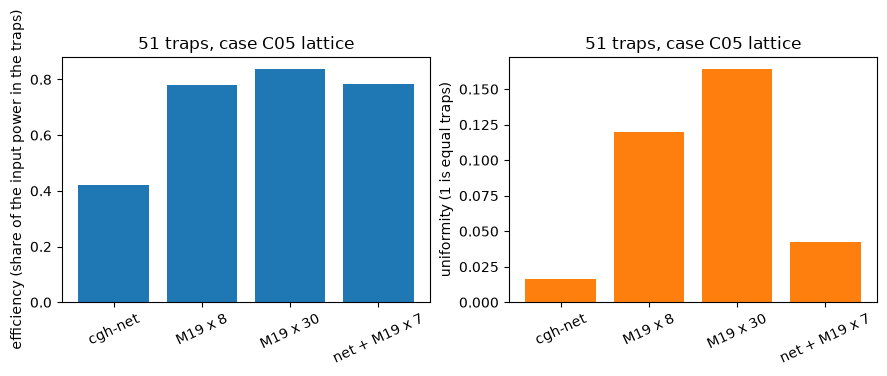

In [12]:
# the same numbers as bars: how much light reaches the traps and how even the traps are
names = list(numbers)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].bar(names, [numbers[n][0] for n in names], color="C0")
axes[0].set_ylabel("efficiency (share of the input power in the traps)")
axes[1].bar(names, [numbers[n][1] for n in names], color="C1")
axes[1].set_ylabel("uniformity (1 is equal traps)")
for ax in axes:
    ax.set_title("51 traps, case C05 lattice")
    ax.tick_params(axis="x", labelrotation=25)
fig.tight_layout()
plt.show()

The bars repeat the table: the network is the lowest in both panels, and M19 at 30 iterations is the highest. The figure shows the trade at one target and says nothing about whether it holds on other targets, since a lattice repeated on three planes is a favourable and unusual case for M19. Eight more volumes test that, drawn by the product's generator with a fixed seed: two each of random sets, lattices, rings and mixed volumes, between 9 and 90 traps. For each the cell runs the network, M19 at 4 and then 8 iterations, the 7-iteration hybrid, and the trap numbers of the network and of M19 at 8.

In [13]:
# eight generated volumes on the held-out setup: the network, M19 at 4 and 8 iterations, the 7 iteration hybrid
bench = evaluation.SETUP128
dz_b = m17_cgh_net.plane_dz_m(bench)
rng = np.random.default_rng(20261028)
rows = []
for kind in ("random", "lattice", "ring", "mixed") * 2:
    a, pts = generators.sample_volume(rng, kind)
    tgt = evaluation.volume_target(pts)
    net_v = m17_cgh_net.run(bench, tgt, budget=Budget(1), rng=Rng(1), refine=False)
    first = m19_multiplane.run(bench, tgt, budget=Budget(4), rng=Rng(1), dz_m=dz_b)
    second = m19_multiplane.run(bench, tgt, budget=Budget(4), rng=Rng(1), init=first.phi, dz_m=dz_b)
    hybrid = m17_cgh_net.run(bench, tgt, budget=Budget(7), rng=Rng(1))
    eff_n, uni_n, _ = trap_numbers(net_v.phi, bench, tgt.traps)
    eff_m, uni_m, _ = trap_numbers(second.phi, bench, tgt.traps)
    rows.append({"kind": kind, "traps": len(pts), "kept": bool(hybrid.meta["refine_kept"]),
                 "net": evaluation.plane_accuracy(a, net_v.phi), "m19_4": evaluation.plane_accuracy(a, first.phi),
                 "m19_8": evaluation.plane_accuracy(a, second.phi), "hybrid": evaluation.plane_accuracy(a, hybrid.phi),
                 "eff_net": eff_n, "eff_m19": eff_m, "uni_net": uni_n, "uni_m19": uni_m})
    print(f"{kind:8s} {len(pts):3d} traps  AC network {rows[-1]['net']:.3f}, M19 x 4 {rows[-1]['m19_4']:.3f}, "
          f"M19 x 8 {rows[-1]['m19_8']:.3f}, hybrid {rows[-1]['hybrid']:.3f}")

random    12 traps  AC network 0.657, M19 x 4 0.594, M19 x 8 0.595, hybrid 0.657
lattice   12 traps  AC network 0.678, M19 x 4 0.590, M19 x 8 0.589, hybrid 0.678
ring      75 traps  AC network 0.708, M19 x 4 0.603, M19 x 8 0.602, hybrid 0.708
mixed     90 traps  AC network 0.678, M19 x 4 0.594, M19 x 8 0.594, hybrid 0.678
random    75 traps  AC network 0.683, M19 x 4 0.592, M19 x 8 0.593, hybrid 0.683
lattice   48 traps  AC network 0.693, M19 x 4 0.617, M19 x 8 0.619, hybrid 0.693
ring       9 traps  AC network 0.656, M19 x 4 0.593, M19 x 8 0.594, hybrid 0.656
mixed      9 traps  AC network 0.671, M19 x 4 0.593, M19 x 8 0.594, hybrid 0.671


The network is above M19 on every row, by 0.06 to 0.11 in accuracy; M19's accuracy hardly moves between 4 and 8 iterations, and the hybrid equals the network on every row, which means the refinement was discarded each time. The next figure draws the four accuracies for every volume.

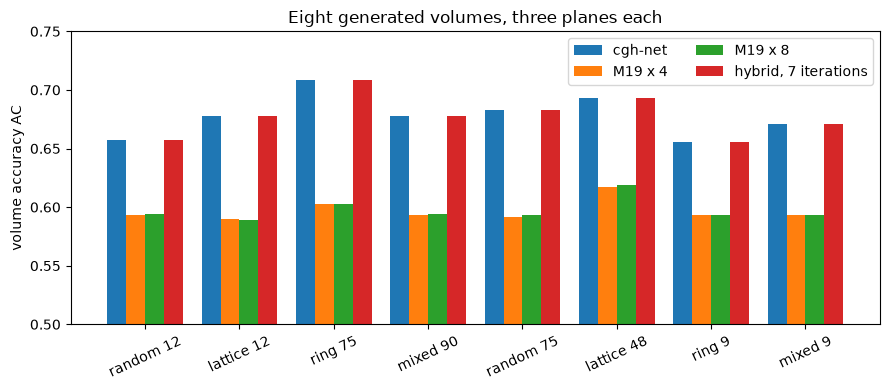

In [14]:
# the accuracy of the four holograms on each of the eight volumes
labels = [f"{r['kind']} {r['traps']}" for r in rows]
x = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(9, 4))
series = (("net", "cgh-net"), ("m19_4", "M19 x 4"), ("m19_8", "M19 x 8"), ("hybrid", "hybrid, 7 iterations"))
for j, (key, name) in enumerate(series):
    ax.bar(x + 0.2 * (j - 1.5), [r[key] for r in rows], width=0.2, label=name)
ax.set_xticks(x, labels, rotation=25)
ax.set_ylim(0.5, 0.75)
ax.set_ylabel("volume accuracy AC")
ax.set_title("Eight generated volumes, three planes each")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

The red bars of the hybrid have the same height as the network's, and the network's bars are above the two M19 bars in every group. The vertical axis starts at 0.5 to make the differences visible, so the bars exaggerate the ratio; the table above has the true ratio. The figure shows a consistent advantage in accuracy across volume kinds and trap counts, and it shows no information about the traps' intensities, which the next cell summarises with the ratios, the number of refinements kept and the traps' medians.

In [15]:
# the ratios the question asks for, and how often the hybrid keeps the refinement
ratio_4 = np.array([r["net"] / r["m19_4"] for r in rows])
ratio_8 = np.array([r["net"] / r["m19_8"] for r in rows])
print(f"network / M19 at 4 iterations: median {np.median(ratio_4):.3f}, smallest {ratio_4.min():.3f}")
print(f"network / M19 at 8 iterations: median {np.median(ratio_8):.3f}, smallest {ratio_8.min():.3f}")
print(f"volumes where the network is above M19 at 8 iterations: {int(np.sum(ratio_8 > 1))} of {len(rows)}")
print(f"refinements kept by the 7 iteration hybrid: {sum(r['kept'] for r in rows)} of {len(rows)}")
print(f"trap efficiency, median: network {np.median([r['eff_net'] for r in rows]):.3f}, "
      f"M19 x 8 {np.median([r['eff_m19'] for r in rows]):.3f}")
print(f"trap uniformity, median: network {np.median([r['uni_net'] for r in rows]):.3f}, "
      f"M19 x 8 {np.median([r['uni_m19'] for r in rows]):.3f}")

network / M19 at 4 iterations: median 1.136, smallest 1.105
network / M19 at 8 iterations: median 1.135, smallest 1.105
volumes where the network is above M19 at 8 iterations: 8 of 8
refinements kept by the 7 iteration hybrid: 0 of 8
trap efficiency, median: network 0.390, M19 x 8 0.716
trap uniformity, median: network 0.575, M19 x 8 0.717


The volumes above are this notebook's own sample. The product's held-out record is larger: the evaluate stage scored the released graph on 162 volumes written before training, against M19 given the same wall clock, and wrote the result to `data/derived/models/metrics.json`. The cell reads it.

In [16]:
# the product's held-out record of the slot: 162 volumes, the hybrid against M19 at the same wall clock
metrics_doc = json.loads((ROOT / "data" / "derived" / "models" / "metrics.json").read_text(encoding="utf-8"))
slot = metrics_doc["slots"]["cgh-net"]
ratio = slot["accuracy_vs_gs"]
print(f"held-out volumes: {slot['held_out_n']}, baseline: {slot['baseline']}")
print(f"accuracy over the baseline: median {ratio['median']:.3f}, quartiles {ratio['q1']:.3f} to {ratio['q3']:.3f}")


held-out volumes: 162, baseline: M19
accuracy over the baseline: median 1.140, quartiles 1.102 to 1.160


## Results

**Answer:** Yes by the volume's accuracy, no by the traps' numbers. On case C05 the network's single pass scores an accuracy of 0.7452, above M19 at every iteration count up to 30 (0.7417), at a cost below one M19 iteration. On the eight generated volumes the network is above M19 at 8 iterations on 8 of 8, with a median ratio of 1.135 (smallest 1.105) at the same cost bound, which is consistent with the 1.140 median the product's evaluation records over 162 volumes at equal wall-clock. The same hologram gives the traps a median efficiency of 0.390 against 0.716 for M19 at 8 iterations, and 0.421 against 0.838 on C05 with 30 iterations. The network is not a better start for M19: the hybrid kept the refinement on 0 of 8 volumes and on none of the three budgets of C05, because the refinement lowers the accuracy that the network was trained to raise.

What the notebook does not show: how the result moves with a metric that rewards equal traps (the product's evaluation scores only $AC$), how it behaves for a volume that is not on the three trained planes (the method refuses such a target with an error), and how it compares with a loop that optimises $AC$ instead of the voxels. The DeepCGH advantage reported in the paper is therefore reproduced in direction on the paper's own measure and does not transfer to the quality that trap arrays are judged by.

## Summary

A three-plane hologram can be judged on the images it makes or on the traps it feeds, and the two judgements can rank the same two holograms in opposite order. The released network gives the higher image accuracy for less than the cost of one iteration of the volumetric loop, on the lattice of case C05 and on eight generated volumes. The classical loop gives the traps more light, and equalises them better, because it optimises them. The hybrid that the method offers keeps the network's phase and discards M19's refinement, so it is the network alone. A user who wants a quick preview of a volume, or a start whose images are right, has a use for the network; a user who needs traps of equal depth needs a trap-aware method. The next notebook of the topic asks the same question for the other learned method of the product, whose network predicts trap phases and was refused.

## References

- Eybposh, Caira, Atisa, Chakravarthula and Pégard, "DeepCGH: 3D computer-generated holography using deep learning", Optics Express 28, 26636 (2020), https://doi.org/10.1364/OE.399624.
- Whyte and Courtial, "Experimental demonstration of holographic three-dimensional light shaping using a Gerchberg-Saxton algorithm", New Journal of Physics 7, 117 (2005), https://doi.org/10.1088/1367-2630/7/1/117.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- The product's model card `models/cgh-net.json` and the evaluation record `data/derived/models/metrics.json` (the 162-volume figure quoted in the Results).